In [2]:
import pyuvdata
import numpy as np
import matplotlib.pyplot as plt

In [3]:
filepath = "/lustre/pipeline/cosmology/41MHz/2026-01-12/12/20260112_120008_41MHz.ms"
# filepath = "/fast/rbyrne/20260112_120008-120158_34MHz_casa_05h_calibrated.uvfits"

In [4]:
uv = pyuvdata.UVData()
uv.read(filepath)

Setting telescope_location to value in known_telescopes for OVRO-LWA.
The uvw_array does not match the expected values given the antenna positions. The largest discrepancy is 6.7540101049759755 meters. This is a fairly common situation but might indicate an error in the antenna positions, the uvws or the phasing.


The uvw_array does not match the expected values given the antenna positions. The largest discrepancy is 6.7540101049759755 meters. This is a fairly common situation but might indicate an error in the antenna positions, the uvws or the phasing.


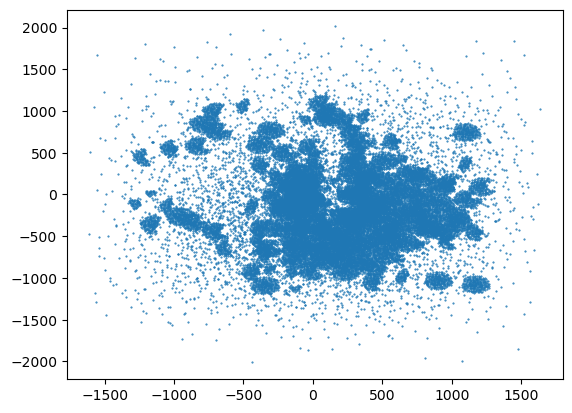

In [5]:
uv.select(polarizations=[-5, -6])
uv.phase_to_time(np.mean(uv.time_array))
plt.plot(uv.uvw_array[:, 0], uv.uvw_array[:, 1], ".", markersize=1)

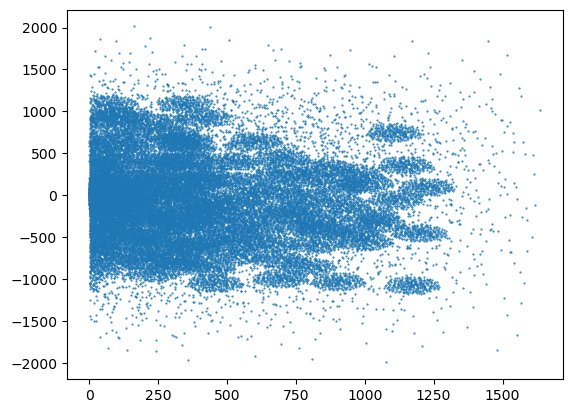

In [6]:
uv.conjugate_bls(convention="u>0")
plt.plot(uv.uvw_array[:, 0], uv.uvw_array[:, 1], ".", markersize=1)

In [7]:
avg_wl = 3e8/np.mean(uv.freq_array)
uv_array_wls = uv.uvw_array[:, :2] / avg_wl

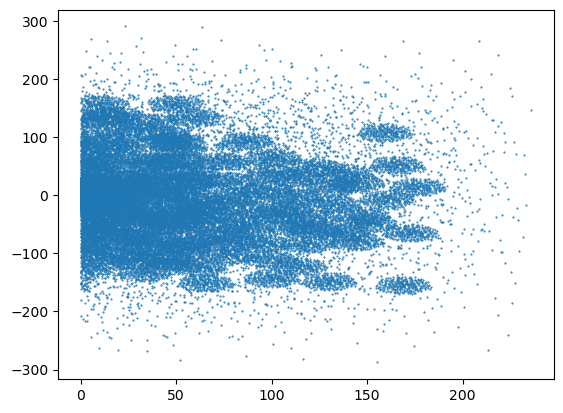

In [8]:
plt.plot(uv_array_wls[:, 0], uv_array_wls[:, 1], ".", markersize=1)

In [9]:
# Bin to half wavelength spacing
# Add flagging support
uv_resolution = 0.5
u_bin_edges = np.arange(0, np.max(uv_array_wls[:, 0]) + uv_resolution, uv_resolution)
v_bin_edges = np.arange(
    0,
    np.max(np.abs(uv_array_wls[:, 1])) + uv_resolution,
    uv_resolution,
)
v_bin_edges = np.append(v_bin_edges[::-1], v_bin_edges[1:])  # Add negative values
u_bin_inds = np.digitize(uv_array_wls[:, 0], u_bin_edges)
v_bin_inds = np.digitize(uv_array_wls[:, 1], u_bin_edges)
visibilities_binned = np.full((len(u_bin_edges)-1, len(v_bin_edges)-1, uv.Nfreqs, uv.Npols), np.nan+1j*np.nan, dtype=complex)
weights = np.zeros((len(u_bin_edges) - 1, len(v_bin_edges) - 1), dtype=int)
for u_ind in range(len(u_bin_edges)-1):
    for v_ind in range(len(v_bin_edges)-1):
        use_inds = np.where((u_bin_inds == u_ind) & (v_bin_inds==v_ind))[0]
        if len(use_inds) > 0:
            weights[u_ind, v_ind] = len(use_inds)
            visibilities_binned[u_ind, v_ind, :, :] = np.nanmean(uv.data_array[use_inds, :, :], axis=0)

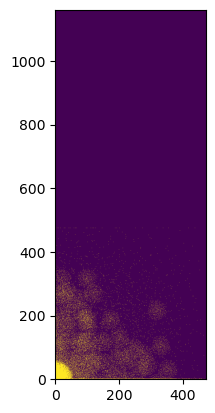

In [10]:
plt.imshow(weights.T, origin="lower", interpolation=None, vmin=0, vmax=1)

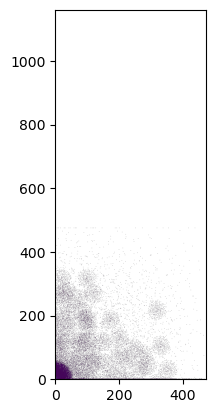

In [11]:
plt.imshow(np.abs(visibilities_binned[:, :, 100, 0]).T, origin="lower", interpolation=None, vmin=0, vmax=1)

In [12]:
visibilities_ft = np.fft.ifft(visibilities_binned, axis=2)  # Fourier transform across frequency
delay_axis = np.fft.fftshift(np.fft.fftfreq(uv.Nfreqs, d=np.mean(uv.channel_width)))

In [13]:
kperp_resolution = 1
u_bin_centers = (u_bin_edges[:-1] + u_bin_edges[1:]) / 2
v_bin_centers = (v_bin_edges[:-1] + v_bin_edges[1:]) / 2
kperp_vals = np.hypot(u_bin_centers[:, None], v_bin_centers[None, :])
kperp_bin_edges = np.arange(0, np.max(kperp_vals)+kperp_resolution, kperp_resolution)
ps_2d = np.zeros((len(kperp_bin_edges)-1, uv.Nfreqs, uv.Npols), dtype=float)
bin_indices = np.digitize(kperp_vals, kperp_bin_edges)
for bin_ind in range(np.max(bin_indices)):
    use_inds = np.where(bin_indices == bin_ind)
    use_vis = visibilities_ft[use_inds[0], use_inds[1], :, :]
    use_weights = weights[use_inds[0], use_inds[1]]
    ps_2d[bin_ind, :, :] = np.nanmean(
        np.abs(use_vis)**2 * use_weights[:, np.newaxis, np.newaxis], axis=0
    ) / np.sum(use_weights)
ps_2d = (ps_2d + ps_2d[:, ::-1, :])[:, np.where(delay_axis == 0)[0][0]:, :] / 2  # Fold in delay

Mean of empty slice


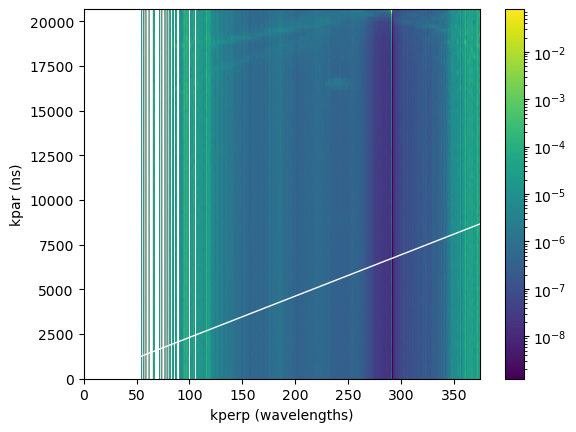

In [14]:
plt.imshow(
    ps_2d[:, :, 0].T,
    origin="lower",
    interpolation=None,
    extent=(np.min(kperp_bin_edges), np.max(kperp_bin_edges), 0, np.max(delay_axis)*1e9),
    aspect="auto",
    norm="log",
)
plt.plot(
    kperp_bin_edges,
    kperp_bin_edges * avg_wl / 3e8 * 1e9,
    "-",
    color="white",
    linewidth=1,
)
plt.xlabel("kperp (wavelengths)")
plt.ylabel("kpar (ns)")
plt.colorbar()